In [11]:
from dotenv import load_dotenv
load_dotenv()

import os
import torch
from pathlib import Path
import pandas as pd
from datasets import Dataset
from transformers import (
    AutoTokenizer, AutoModelForCausalLM,
    TrainingArguments, Trainer, DataCollatorForSeq2Seq,
)
from peft import LoraConfig, get_peft_model, TaskType

In [12]:
dataset_path = Path(os.getenv("DATASET_PATH"))
model_path   = Path(os.getenv("MODEL_PATH"))
LORA_DIR     = Path(r"D:\projects\jupyter\jupyter\llm选修课\实验\Exp06\work\LoRA")
LORA_DIR.mkdir(parents=True, exist_ok=True)

device = "cuda" if torch.cuda.is_available() else "cpu"
dtype  = torch.float16 if device == "cuda" else torch.float32

tokenizer = AutoTokenizer.from_pretrained(
    str(model_path), local_files_only=True, trust_remote_code=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(
    str(model_path),
    dtype=dtype,
    local_files_only=True,
    trust_remote_code=True,
).to(device)

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

In [13]:
df  = pd.read_json(dataset_path / "train_alpaca.json", encoding="utf-8")
raw = Dataset.from_pandas(df[["instruction", "input", "output"]])

def preprocess(ex):
    prompt = f"### Instruction:\n{ex['instruction']}\n"
    if ex["input"]:
        prompt += f"### Input:\n{ex['input']}\n"
    prompt += "### Response:\n"

    prompt_ids = tokenizer(prompt, add_special_tokens=False)["input_ids"]
    answer_ids = tokenizer(ex["output"], add_special_tokens=False)["input_ids"] + [tokenizer.eos_token_id]

    input_ids = prompt_ids + answer_ids
    labels    = [-100] * len(prompt_ids) + answer_ids
    return {"input_ids": input_ids, "labels": labels, "attention_mask": [1] * len(input_ids)}

train_ds = raw.map(preprocess, remove_columns=raw.column_names)

Map:   0%|          | 0/78 [00:00<?, ? examples/s]

In [14]:
lora_config = LoraConfig(
    task_type=TaskType.CAUSAL_LM,
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj"],
    bias="none",
)
model = get_peft_model(model, lora_config)
model.print_trainable_parameters()

trainable params: 1,081,344 || all params: 495,114,112 || trainable%: 0.2184


In [16]:
training_args = TrainingArguments(
    output_dir=str(LORA_DIR),
    num_train_epochs=10,
    learning_rate=5e-5,
    per_device_train_batch_size=4,
    gradient_accumulation_steps=4,
    warmup_steps=0.1,
    logging_steps=1,
    save_strategy="no",
    report_to="none",
    fp16=(device == "cuda"),
    dataloader_pin_memory=(device == "cuda"),
    remove_unused_columns=False,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    data_collator=DataCollatorForSeq2Seq(tokenizer, padding=True),
)
trainer.train()

Step,Training Loss
1,3.468774
2,3.529142
3,3.152686
4,4.268598
5,3.504517
6,3.219386
7,3.027712
8,4.049046
9,3.834789
10,3.264846


TrainOutput(global_step=50, training_loss=3.2119134044647217, metrics={'train_runtime': 841.2317, 'train_samples_per_second': 0.927, 'train_steps_per_second': 0.059, 'total_flos': 125028236771328.0, 'train_loss': 3.2119134044647217, 'epoch': 10.0})

In [17]:
model.save_pretrained(LORA_DIR)
tokenizer.save_pretrained(LORA_DIR)

('D:\\projects\\jupyter\\jupyter\\llm选修课\\实验\\Exp06\\work\\LoRA\\tokenizer_config.json',
 'D:\\projects\\jupyter\\jupyter\\llm选修课\\实验\\Exp06\\work\\LoRA\\chat_template.jinja',
 'D:\\projects\\jupyter\\jupyter\\llm选修课\\实验\\Exp06\\work\\LoRA\\tokenizer.json')

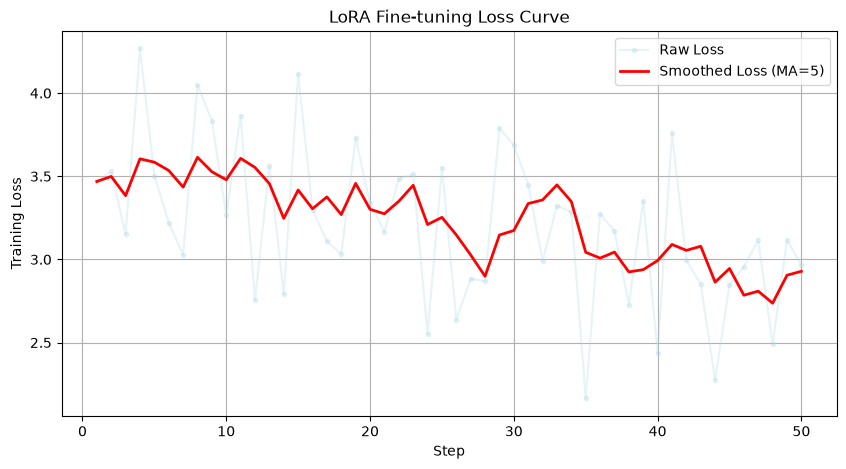

In [18]:
import matplotlib.pyplot as plt

hist   = trainer.state.log_history
steps  = [x["step"] for x in hist if "loss" in x]
losses = [x["loss"] for x in hist if "loss" in x]

loss_series = pd.Series(losses)
smooth_loss = loss_series.rolling(window=5, min_periods=1).mean()

plt.figure(figsize=(10, 5))
plt.plot(steps, losses, alpha=0.3, label="Raw Loss", color="lightblue", marker=".")
plt.plot(steps, smooth_loss, label="Smoothed Loss (MA=5)", color="red", linewidth=2)

plt.xlabel("Step")
plt.ylabel("Training Loss")
plt.title("LoRA Fine-tuning Loss Curve")
plt.legend()
plt.grid(True)
plt.show()